# COU 07506 Digital Signal Processing — Week 01: Lab 0 Setting Up the DSP Laboratory
Name: Nickson Pascal Ngowi  Registration No.: 240242499465
Class: BENG24COE Group:06 Date: 25 November 2026
Instructor checkpoints signed: [ ] 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

## Pre-lab
Three devices that contain DSP and the signal each processes:
1. Smartphone: processes speech (microphone signal) for calls, noise reduction and voice assistants.
2. Pulse oximeter / smartwatch: processes the light-absorption (PPG) signal to find pulse rate and oxygen level.
3. Car radio / digital TV decoder: processes the received broadcast signal (FM / DVB) to recover audio and video.

## Task 1.1 — Your first notebook

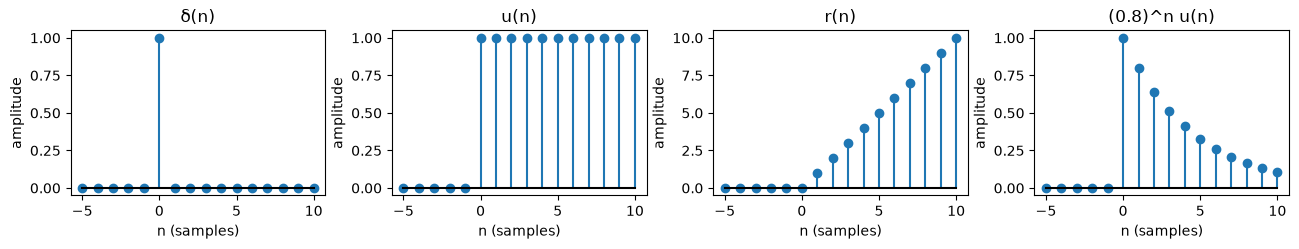

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)   # unit impulse
step  = (n >= 0).astype(float)   # unit step
ramp  = n * step                 # unit ramp
expo  = 0.8**n * step            # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, ttl in zip(axes, [delta, step, ramp, expo],
                      ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(ttl); ax.set_xlabel("n (samples)"); ax.set_ylabel("amplitude")
plt.tight_layout(); plt.show()

## Task 1.2 — Change the parameters

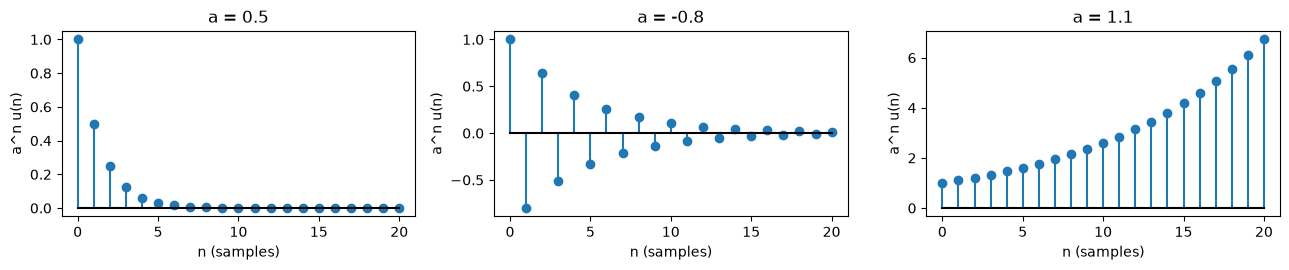

In [3]:
n = np.arange(0, 21)
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, (a**n.astype(float)), basefmt="k-")
    ax.set_title(f"a = {a}"); ax.set_xlabel("n (samples)"); ax.set_ylabel("a^n u(n)")
plt.tight_layout(); plt.show()

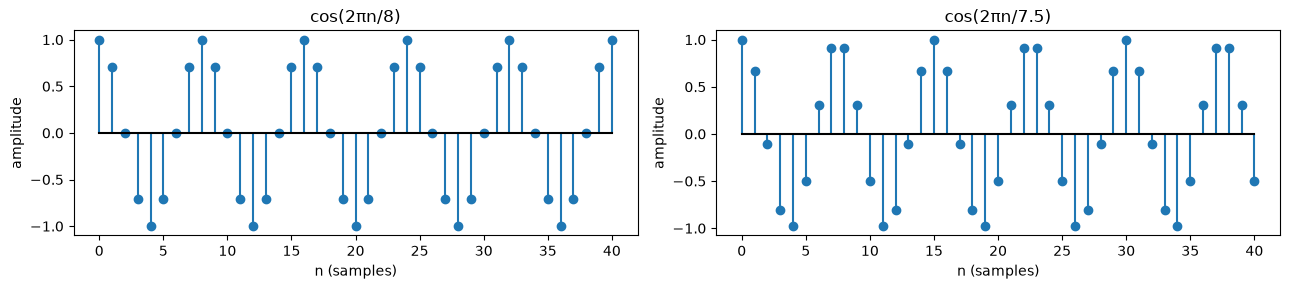

In [4]:
n = np.arange(0, 41)
fig, axes = plt.subplots(1, 2, figsize=(13, 3))
axes[0].stem(n, np.cos(2*np.pi*n/8), basefmt="k-");   axes[0].set_title("cos(2πn/8)")
axes[1].stem(n, np.cos(2*np.pi*n/7.5), basefmt="k-"); axes[1].set_title("cos(2πn/7.5)")
for ax in axes: ax.set_xlabel("n (samples)"); ax.set_ylabel("amplitude")
plt.tight_layout(); plt.show()

**Which one repeats exactly?**
cos(2πn/8) has ω0 = π/4, so it repeats exactly every N = 8 samples (the plot shows an identical pattern every 8 samples).
cos(2πn/7.5) has frequency f0 = 1/7.5 = 2/15 cycles/sample. A discrete-time sinusoid is periodic only if 2π/ω0 is an integer, or a ratio of integers, number of samples. Here the period is not 7.5 (n must be an integer); the pattern only repeats after N = 15 samples (2 cycles). So it does not repeat after 7 or 8 samples, and it looks irregular next to the first one. This is the discrete-time periodicity condition: a sinusoid is periodic only if f0 is a rational number.

## Task 1.3 — Working with audio
Put your recording as `my_voice.wav` in the same folder as this notebook. If it is missing, the fallback signal is used.

fs = 16000 Hz, duration = 2.00 s, samples = 32000


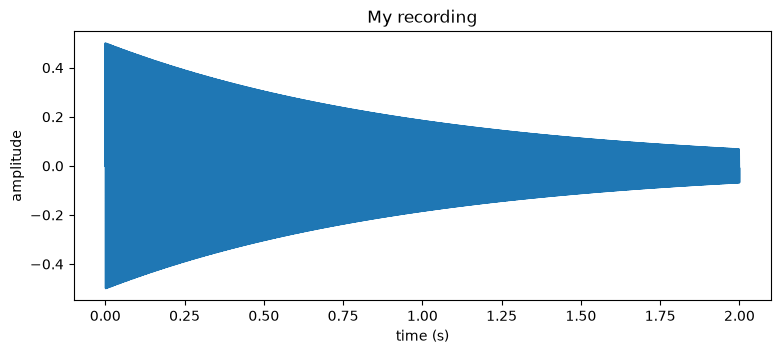

In [5]:
import os
fname = "my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)
    x = x.astype(float)
    x = x / np.max(np.abs(x))
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()

In [6]:
from IPython.display import Audio
Audio(x, rate=fs)

## Task 1.5 — Repository
Git repository link: https://github.com/Nickson-Nicky/COU07506-labs

(Commands used: `git init`, `git add .`, `git commit -m "Weeks 1-3"`, then pushed to GitHub.)

## Analysis questions
1. The sampling rate of a phone recording is normally 44100 Hz or 48000 Hz (my notebook prints the exact value in Task 1.3; the fallback signal uses 16000 Hz). One minute of mono audio needs 60 × fs numbers: 2 646 000 at 44.1 kHz, 2 880 000 at 48 kHz (960 000 at 16 kHz).
2. x(n) is defined only at integer values of n and has no values in between. A stem plot shows isolated samples, whereas a continuous line would wrongly suggest that the signal exists between the samples.
3. For a = 1.1 the sequence 1.1^n grows without bound. If it were an impulse response, Σ|h(n)| would be infinite, so the system would violate BIBO stability (a bounded input would give an unbounded output).